---
title: "Linear ODEs, Fourier Series and Transforms"
short_title: "M4 Oscillation Math"
numbering:
  heading_2: true
  equation: true
---

# Linear ODEs, Fourier Series and Transforms

:::{tip} Where this sits in the plan
Math for **oscillations** (and later normal modes and orbits).

| Item | Stewart | Boas | Zill | Arfken |
|---|---|---|---|---|
| Second-order linear ODEs | 17 | 8 | 3 | 7 |
| Complex numbers and Euler's formula | App. H | 2 | 17 | 11 |
| Fourier series | – | 7 | 12 | 19 |
| Green's functions for ODEs | – | 8 | 3 | 10 |
| Laplace transforms | – | 8 | 4 | 20 |

Chapter numbers are approximate, as in the workbook.
:::

Complex exponentials were introduced in M1. Here they become the main tool. Exercises have separate hint and answer dropdowns.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [Oscillations](../mechanics/05-oscillations.ipynb). If you miss a part, study just the section it names and try that problem again.

1. **Second-Order Linear ODEs with Constant Coefficients**: the homogeneous equation

   (a) Solve $\ddot x + 6\dot x + 9x = 0$ with $x(0) = 1$, $\dot x(0) = 0$.

   (b) Find the general solution of $\ddot x + 2\dot x + 5x = 0$. Is it under-, over- or critically damped?

   (c) Solve $\ddot x - x = 0$ with $x(0) = 0$, $\dot x(0) = 1$.

2. **Second-Order Linear ODEs with Constant Coefficients**: the inhomogeneous equation

   (a) Find a particular solution of $\ddot x + 4x = 3e^{-t}$.

   (b) For $\ddot x + 2\beta\dot x + \omega_0^2x = f_0\cos\omega t$, give the steady-state amplitude and the phase lag $\delta$.

   (c) Find a particular solution of $\ddot x + x = \cos t$. Why does the usual guess $A\cos t$ fail?

3. **Fourier Series**

   (a) Find the Fourier series of the sawtooth $f(t) = t$ on $(-\pi, \pi)$, repeated with period $2\pi$.

   (b) Why do its coefficients fall off only as $1/n$?

   (c) A periodic force of period $\tau$ drives a lightly damped oscillator with natural frequency $\omega_0 = 3(2\pi/\tau)$. Which harmonic of the force produces a large response?

4. **Green's Functions**

   (a) For $\dot x + \gamma x = f(t)$, find the Green's function $G(t)$, the response to $f = \delta(t)$ starting from rest.

   (b) Use it to find $x(t)$ for $f = f_0$ switched on at $t = 0$.

   (c) An undamped oscillator of mass $m$ and natural frequency $\omega_0$ is at rest when it receives an impulse $J$ at $t = 0$. Find $x(t)$.

5. **Laplace Transforms**

   (a) Give $\mathcal{L}\{e^{at}\}$ and $\mathcal{L}\{\sin\omega t\}$.

   (b) Use the Laplace transform to solve $\dot x - 2x = e^t$ with $x(0) = 0$.

:::{dropdown} Answers
1. (a) The characteristic equation has a double root $r = -3$, so $x = (1 + 3t)e^{-3t}$ (critically damped).

   (b) The roots are $r = -1 \pm 2i$, so $x = e^{-t}(A\cos2t + B\sin2t)$. Underdamped.

   (c) $x = \sinh t$.

2. (a) $x_p = \tfrac35e^{-t}$.

   (b) $A = \dfrac{f_0}{\sqrt{(\omega_0^2 - \omega^2)^2 + 4\beta^2\omega^2}}$ and $\tan\delta = \dfrac{2\beta\omega}{\omega_0^2 - \omega^2}$.

   (c) $x_p = \tfrac12t\sin t$. The guess $A\cos t$ fails because $\cos t$ already solves the homogeneous equation (resonance).

3. (a) $f$ is odd, so it is a sine series: $b_n = \dfrac{2(-1)^{n+1}}{n}$, giving $t = 2\left(\sin t - \tfrac12\sin2t + \tfrac13\sin3t - \cdots\right)$.

   (b) The periodic extension jumps at $t = \pm\pi$. A discontinuity gives $1/n$ coefficients; a continuous function with a kink (like the triangle wave) gives $1/n^2$.

   (c) The third harmonic, $n = 3$.

4. (a) $G(t) = e^{-\gamma t}$ for $t > 0$, and $0$ for $t < 0$.

   (b) $x = \int_0^tf_0e^{-\gamma(t - t')}dt' = \dfrac{f_0}{\gamma}\left(1 - e^{-\gamma t}\right)$.

   (c) $x = \dfrac{J}{m\omega_0}\sin\omega_0t$.

5. (a) $\dfrac{1}{s - a}$ and $\dfrac{\omega}{s^2 + \omega^2}$.

   (b) $(s - 2)X = \dfrac{1}{s - 1}$, so $X = \dfrac{1}{s - 2} - \dfrac{1}{s - 1}$ and $x = e^{2t} - e^t$.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
g = 9.81  # m/s^2

## Second-Order Linear ODEs with Constant Coefficients

The equation behind every damped oscillator, RLC circuit and small vibration is

$$
\ddot x + 2\beta\dot x + \omega_0^2x = f(t) .
$$ (eq-linear-2nd)

### The homogeneous equation

With $f = 0$, try $x = e^{rt}$. Every derivative becomes a factor of $r$, so the ODE becomes the **characteristic equation**

$$
r^2 + 2\beta r + \omega_0^2 = 0 \quad\Longrightarrow\quad r_\pm = -\beta\pm\sqrt{\beta^2 - \omega_0^2} .
$$

Because the equation is linear and homogeneous, any combination $c_+e^{r_+t} + c_-e^{r_-t}$ is a solution, and two constants match the two initial conditions $x(0)$, $\dot x(0)$. The sign under the square root sorts the solutions into three cases:

| Case | Roots | General solution |
|---|---|---|
| $\beta < \omega_0$ (underdamped) | complex, $-\beta\pm i\omega_1$ with $\omega_1 = \sqrt{\omega_0^2 - \beta^2}$ | $e^{-\beta t}\big(A\cos\omega_1t + B\sin\omega_1t\big)$ |
| $\beta = \omega_0$ (critical) | repeated, $-\beta$ | $(A + Bt)\,e^{-\beta t}$ |
| $\beta > \omega_0$ (overdamped) | two negative reals | $c_+e^{r_+t} + c_-e^{r_-t}$ |

The repeated-root case needs the extra $te^{-\beta t}$, because a single exponential cannot match two initial conditions. You can check that $te^{rt}$ solves the equation exactly when $r$ is a double root.

In [2]:
# Let sympy produce the general solution in each regime
t = sp.symbols("t", real=True)
x = sp.Function("x")
for beta, w0 in [(1, 3), (3, 3), (5, 3)]:
    ode = sp.Eq(x(t).diff(t, 2) + 2 * beta * x(t).diff(t) + w0**2 * x(t), 0)
    display(Math(r"\beta = " + str(beta) + r",\ \omega_0 = " + str(w0) + r":\quad x(t) = " + sp.latex(sp.dsolve(ode).rhs)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### The inhomogeneous equation

For $f\neq0$, the general solution is

$$
x(t) = x_p(t) + x_h(t) ,
$$

any one **particular** solution plus the general homogeneous solution. When $\beta > 0$ the homogeneous part decays, so it is the **transient**, and $x_p$ is the long-time behavior.

For sinusoidal forcing, complex exponentials do the work. Replace $\cos\omega t$ by $e^{i\omega t}$, guess $x_p = Ce^{i\omega t}$, and take the real part at the end:

$$
\left(-\omega^2 + 2i\beta\omega + \omega_0^2\right)C = f_0
\quad\Longrightarrow\quad
C = H(\omega)\,f_0, \qquad H(\omega) = \frac{1}{\omega_0^2 - \omega^2 + 2i\beta\omega} .
$$ (eq-transfer)

$H(\omega)$ is the **transfer function** (or frequency response). Its magnitude is the amplitude per unit forcing and its argument is the phase shift. All of resonance is in this one complex number.

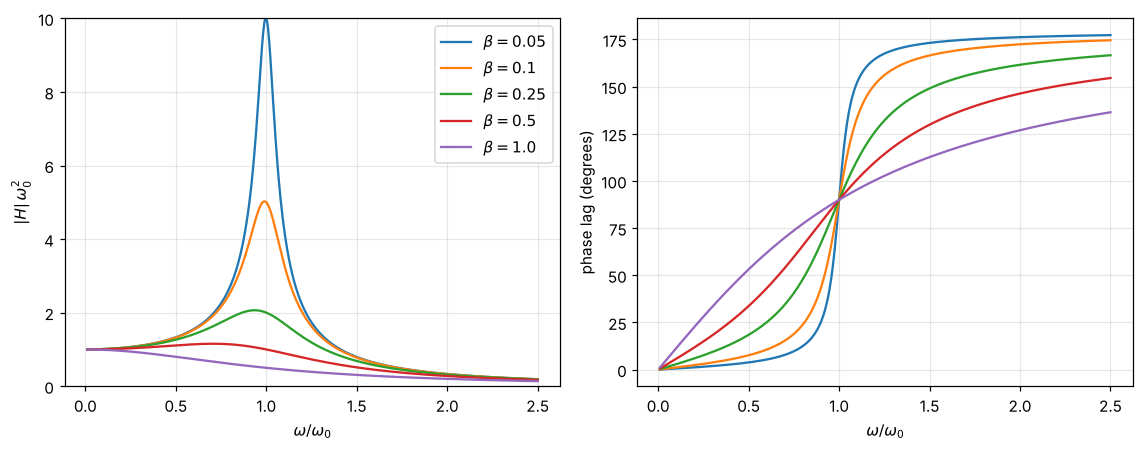

In [3]:
#| label: fig-transfer
#| caption: The transfer function H(ω) of the damped oscillator, for ω₀ = 1 and several damping rates β. Left, the magnitude peaks near ω₀ when damping is light. Right, the phase lag passes through 90° at ω = ω₀ for every β.
w = np.linspace(0.01, 2.5, 800)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for beta in [0.05, 0.1, 0.25, 0.5, 1.0]:
    H = 1 / (1 - w**2 + 2j * beta * w)
    axes[0].plot(w, np.abs(H), label=rf"$\beta = {beta}$")
    axes[1].plot(w, -np.degrees(np.angle(H)))
axes[0].set_ylim(0, 10); axes[0].set_xlabel(r"$\omega/\omega_0$"); axes[0].set_ylabel(r"$|H|\,\omega_0^2$"); axes[0].legend()
axes[1].set_xlabel(r"$\omega/\omega_0$"); axes[1].set_ylabel("phase lag (degrees)")
plt.tight_layout(); plt.show()

### Exercises

1. Solve $\ddot x + 4x = 0$ with $x(0) = 1$, $\dot x(0) = 2$.
2. Solve $\ddot x + 2\dot x + x = 0$ with $x(0) = 0$, $\dot x(0) = 1$.
3. Find the steady-state solution of $\ddot x + \dot x + x = \cos t$.

:::{dropdown} Hints
1. The roots are $\pm2i$.
2. This is the critically damped case.
3. Evaluate $H(1)$ from {eq}`eq-transfer` with $\omega_0 = 1$, $2\beta = 1$.
:::

:::{dropdown} Answers
1. $x = \cos2t + \sin2t$.
2. $x = te^{-t}$.
3. $H(1) = 1/i = -i$, so $x_p = \operatorname{Re}(-ie^{it}) = \sin t$: the response lags the drive by $90^\circ$.
:::

## Fourier Series

A periodic driving force is rarely a pure sinusoid. **Fourier series** break any reasonable periodic function into sinusoids, and linearity lets us handle each one with $H(\omega)$ separately.

:::{prf:theorem} Fourier series
:label: thm-fourier

A function $f$ with period $T$ (and $\omega = 2\pi/T$) that is piecewise smooth can be written as

$$
f(t) = \frac{a_0}{2} + \sum_{n=1}^\infty\big(a_n\cos n\omega t + b_n\sin n\omega t\big),
$$

with

$$
a_n = \frac2T\int_{-T/2}^{T/2}f(t)\cos n\omega t\,dt, \qquad b_n = \frac2T\int_{-T/2}^{T/2}f(t)\sin n\omega t\,dt .
$$ (eq-fourier-coeffs)

At a jump, the series converges to the midpoint of the jump.
:::

**Why the coefficient formulas work.** Over one period, the functions $\cos n\omega t$ and $\sin n\omega t$ are **orthogonal**: the integral of the product of any two different ones is zero. Multiply the series by $\cos m\omega t$, integrate, and every term except the $m$-th vanishes. This is the same idea as finding a vector's component with a dot product, and it reappears in normal modes, Legendre polynomials and quantum mechanics.

The **complex form** is often cleaner: $f(t) = \sum_{n=-\infty}^{\infty}c_ne^{in\omega t}$ with $c_n = \frac1T\int f(t)e^{-in\omega t}\,dt$.

::::{prf:example} A square wave
:label: ex-square-wave

Find the Fourier series of the square wave $f(t) = +1$ for $0 < t < T/2$ and $-1$ for $-T/2 < t < 0$.

:::{dropdown} Solution
The function is odd, so every $a_n = 0$. For the sines,

$$
b_n = \frac4T\int_0^{T/2}\sin n\omega t\,dt = \frac{2}{n\pi}\big(1 - \cos n\pi\big) = \begin{cases} 4/(n\pi) & n \text{ odd} \\ 0 & n \text{ even}\end{cases}
$$

So $f(t) = \dfrac4\pi\left(\sin\omega t + \tfrac13\sin3\omega t + \tfrac15\sin5\omega t + \cdots\right)$. The coefficients fall off like $1/n$, slowly, because the function jumps.
:::
::::

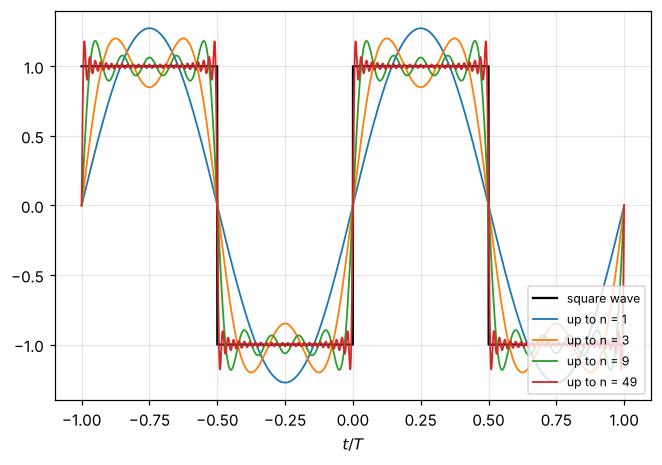

In [4]:
#| label: fig-gibbs
#| caption: Partial sums of the square-wave series. They converge everywhere except right at the jumps, where an overshoot of about 9% of the jump never goes away (the Gibbs phenomenon); it only gets narrower.
t = np.linspace(-1, 1, 3000)        # period T = 1
w = 2 * np.pi
fig, ax = plt.subplots()
ax.plot(t, np.sign(np.sin(w * t)), "k", lw=1.5, label="square wave")
for N, c in [(1, "tab:blue"), (3, "tab:orange"), (9, "tab:green"), (49, "tab:red")]:
    s = sum(4 / (n * np.pi) * np.sin(n * w * t) for n in range(1, N + 1, 2))
    ax.plot(t, s, color=c, lw=1.2, label=f"up to n = {N}")
ax.set_ylim(-1.4, 1.4); ax.set_xlabel("$t/T$"); ax.legend(fontsize=8, loc="lower right")
plt.show()

In [5]:
# Fourier coefficients computed symbolically for a triangle wave |t| on (-1/2, 1/2), period 1
t, n = sp.symbols("t n", real=True)
n_ = sp.symbols("n", integer=True, positive=True)
T = sp.Integer(1); w = 2 * sp.pi
a0 = 2 / T * sp.integrate(sp.Abs(t), (t, -sp.Rational(1, 2), sp.Rational(1, 2)))
an = 2 / T * 2 * sp.integrate(t * sp.cos(n_ * w * t), (t, 0, sp.Rational(1, 2)))   # |t| is even
display(Math("a_0 = " + sp.latex(a0)))
display(Math("a_n = " + sp.latex(sp.simplify(an))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Exercises

1. Explain from symmetry why the Fourier series of an even function contains only cosines.
2. For the triangle wave $|t|$ on $(-\tfrac12, \tfrac12)$, the code gives $a_n$. Simplify it for odd and even $n$, and say why the coefficients fall off faster than the square wave's.

:::{dropdown} Hints
1. The integrand $f(t)\sin n\omega t$ is then odd.
2. $(-1)^n - 1$ is $0$ or $-2$.
:::

:::{dropdown} Answers
1. An odd integrand over a symmetric interval integrates to zero, so every $b_n = 0$.
2. $a_n = -2/(n^2\pi^2)$ for odd $n$ and $0$ for even $n$. The triangle wave is continuous (only its slope jumps), so its coefficients fall like $1/n^2$ rather than $1/n$.
:::

## Green's Functions

Section by section the same idea keeps appearing: a linear system's response to a sharp kick determines its response to everything. Make that precise.

:::{prf:definition} Green's function
:label: def-green

For the linear operator $\mathcal{L}x = \ddot x + 2\beta\dot x + \omega_0^2x$, the **Green's function** $G(t)$ is the solution of

$$
\mathcal{L}G = \delta(t), \qquad G(t) = 0 \text{ for } t < 0 .
$$
:::

Any force is a sum of kicks, $f(t) = \int f(t')\,\delta(t - t')\,dt'$. Linearity then says the response is the same sum of shifted Green's functions:

$$
x(t) = \int_{-\infty}^{t}G(t - t')\,f(t')\,dt' .
$$ (eq-green-solution)

### Finding $G$ for the damped oscillator

For $t > 0$ there is no force, so $G$ solves the homogeneous equation. Integrating $\mathcal{L}G = \delta$ across $t = 0$ shows $G$ is continuous but $\dot G$ jumps by $1$. So $G(0^+) = 0$ and $\dot G(0^+) = 1$, which for the underdamped case gives

$$
G(t) = \frac{1}{\omega_1}\,e^{-\beta t}\sin\omega_1t\;\Theta(t) .
$$ (eq-green-oscillator)

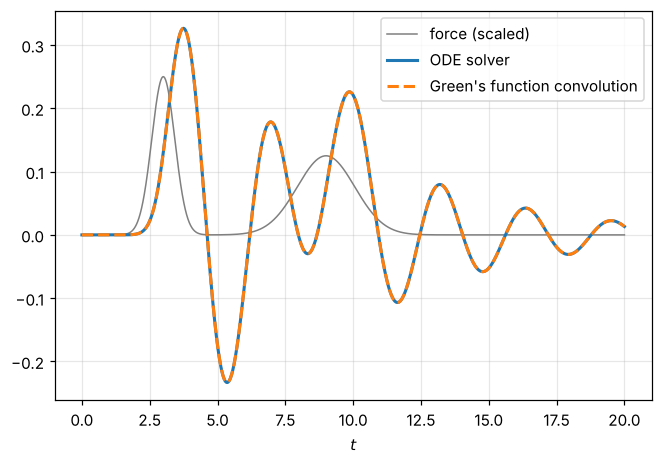

In [6]:
#| label: fig-green-check
#| caption: Response to a smooth pulse of force computed two ways, from the convolution integral with the Green's function (dashed) and by solving the ODE directly (solid). They agree.
beta, w0 = 0.2, 2.0
w1 = np.sqrt(w0**2 - beta**2)
G = lambda s: np.where(s > 0, np.exp(-beta * s) * np.sin(w1 * s) / w1, 0.0)
f = lambda s: np.exp(-((s - 3) / 0.6)**2) + 0.5 * np.exp(-((s - 9) / 1.5)**2)

t = np.linspace(0, 20, 2001)
dt = t[1] - t[0]
x_conv = np.array([np.sum(G(ti - t[: i + 1]) * f(t[: i + 1])) * dt for i, ti in enumerate(t)])
sol = solve_ivp(lambda s, y: [y[1], f(s) - 2 * beta * y[1] - w0**2 * y[0]], (0, 20), [0, 0], t_eval=t, rtol=1e-9)

fig, ax = plt.subplots()
ax.plot(t, f(t) / 4, color="gray", lw=1, label="force (scaled)")
ax.plot(t, sol.y[0], lw=2, label="ODE solver")
ax.plot(t, x_conv, "--", lw=2, label="Green's function convolution")
ax.set_xlabel("$t$"); ax.legend(); plt.show()

## Laplace Transforms

The **Laplace transform** turns a linear ODE with initial conditions into algebra:

$$
X(s) = \mathcal{L}\{x\}(s) = \int_0^\infty x(t)\,e^{-st}\,dt .
$$

The key property comes from integrating by parts:

$$
\mathcal{L}\{\dot x\} = sX - x(0), \qquad \mathcal{L}\{\ddot x\} = s^2X - s\,x(0) - \dot x(0) .
$$ (eq-laplace-deriv)

Derivatives become multiplication by $s$, and the initial conditions are built in. A short table covers most mechanics problems:

| $x(t)$ | $X(s)$ |
|---|---|
| $1$ | $1/s$ |
| $e^{at}$ | $1/(s - a)$ |
| $\sin\omega t$ | $\omega/(s^2 + \omega^2)$ |
| $\cos\omega t$ | $s/(s^2 + \omega^2)$ |
| $e^{-\beta t}\sin\omega t$ | $\omega/\big((s + \beta)^2 + \omega^2\big)$ |
| $\delta(t - a)$ | $e^{-as}$ |

**The recipe.** Transform the ODE, solve the algebraic equation for $X(s)$, split it into partial fractions, and read the answer off the table. Transforming $\mathcal{L}G = \delta$ gives

$$
\widetilde G(s) = \frac{1}{s^2 + 2\beta s + \omega_0^2} ,
$$

the transfer function again, with $s = i\omega$. The Green's function, the transfer function and the Laplace transform are three views of one object.

In [7]:
# Laplace transform solution of x'' + 4x = sin t, x(0) = 0, x'(0) = 1
t, s = sp.symbols("t s", positive=True)
X = sp.symbols("X")
rhs = sp.laplace_transform(sp.sin(t), t, s, noconds=True)
eq = sp.Eq(s**2 * X - 0 * s - 1 + 4 * X, rhs)          # transformed ODE
Xs = sp.solve(eq, X)[0]
display(Math("X(s) = " + sp.latex(sp.apart(sp.simplify(Xs), s))))
x = sp.inverse_laplace_transform(Xs, s, t)
display(Math("x(t) = " + sp.latex(sp.simplify(x))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Exercises

1. Use the Laplace transform to solve $\dot x + 3x = 0$, $x(0) = 2$.
2. Verify that {eq}`eq-green-oscillator` has $G(0^+) = 0$ and $\dot G(0^+) = 1$, and show that its Laplace transform is $1/(s^2 + 2\beta s + \omega_0^2)$.
3. Use {eq}`eq-green-solution` to find the response of an undamped oscillator ($\beta = 0$) at rest to a constant force $f_0$ switched on at $t = 0$.

:::{dropdown} Hints
1. $sX - 2 + 3X = 0$.
2. Use the table entry for $e^{-\beta t}\sin\omega t$ and $\omega_1^2 + \beta^2 = \omega_0^2$.
3. $x(t) = \frac{f_0}{\omega_0}\int_0^t\sin\omega_0(t - t')\,dt'$.
:::

:::{dropdown} Answers
1. $X = 2/(s + 3)$, so $x = 2e^{-3t}$.
2. $\frac{1}{\omega_1}\cdot\frac{\omega_1}{(s+\beta)^2 + \omega_1^2} = \frac{1}{s^2 + 2\beta s + \omega_0^2}$.
3. $x = \frac{f_0}{\omega_0^2}(1 - \cos\omega_0t)$: it oscillates about the new equilibrium $f_0/\omega_0^2$, reaching twice that displacement.
:::

## Summary

- Constant-coefficient linear ODEs reduce to a characteristic polynomial. Its roots give exponentials, oscillations, or $te^{rt}$ for repeated roots.
- General solution = particular + homogeneous. Damping makes the homogeneous part a decaying transient.
- Complex exponentials turn sinusoidal forcing into algebra through the transfer function $H(\omega)$.
- Fourier series split periodic functions into harmonics using orthogonality, so each harmonic can be handled with $H(n\omega)$.
- The Green's function (the impulse response) gives the response to any force by convolution.
- Laplace transforms do the same job with initial conditions built in, and the Laplace transform of $G$ is the transfer function.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.